In [ ]:
import pandas as pd
import numpy as np



bat_rpa = pd.read_csv("outputs/batting_rpa_first_innings.csv")
bowl_rpa = pd.read_csv("outputs/bowling_rpa_first_innings.csv")
wpa = pd.read_csv("outputs/player_wpa_master_all_time.csv")



bat_rpa = bat_rpa.rename(columns={
    "batter": "player",
    "total_rpa": "bat_rpa_raw"
})

bowl_rpa = bowl_rpa.rename(columns={
    "bowler": "player",
    "total_rpa": "bowl_rpa_raw",
    "balls_bowled": "bowl_balls"
})

# Flip sign ONCE for bowling RPA
bowl_rpa["bowl_rpa_raw"] = - bowl_rpa["bowl_rpa_raw"]

wpa = wpa.rename(columns={
    "batting_wpa_total": "bat_wpa_raw",
    "bowling_wpa_total": "bowl_wpa_raw"
})

# Flip sign ONCE for bowling WPA
wpa["bowl_wpa_raw"] = - wpa["bowl_wpa_raw"]



df = (
    bat_rpa[["player", "bat_rpa_raw", "balls_faced"]]
    .merge(
        bowl_rpa[["player", "bowl_rpa_raw", "bowl_balls"]],
        on="player",
        how="outer"
    )
    .merge(
        wpa[[
            "player",
            "bat_wpa_raw",
            "bowl_wpa_raw",
            "balls_faced",
            "balls_bowled"
        ]],
        on="player",
        how="outer",
        suffixes=("_rpa", "_wpa")
    )
)



for col in ["bat_rpa_raw", "bowl_rpa_raw", "bat_wpa_raw", "bowl_wpa_raw"]:
    df[col] = df[col].fillna(0)



df["bat_rpa_eligible"] = df["balls_faced_rpa"].fillna(0) >= 100
df["bowl_rpa_eligible"] = df["bowl_balls"].fillna(0) >= 100

df["bat_wpa_eligible"] = df["balls_faced_wpa"].fillna(0) >= 200
df["bowl_wpa_eligible"] = df["balls_bowled"].fillna(0) >= 200



def zscore(series, mask):
    mu = series[mask].mean()
    sigma = series[mask].std(ddof=0)
    return (series - mu) / sigma



df["bat_rpa_z"] = 0.0
df.loc[df["bat_rpa_eligible"], "bat_rpa_z"] = zscore(
    df["bat_rpa_raw"],
    df["bat_rpa_eligible"]
)

df["bowl_rpa_z"] = 0.0
df.loc[df["bowl_rpa_eligible"], "bowl_rpa_z"] = zscore(
    df["bowl_rpa_raw"],
    df["bowl_rpa_eligible"]
)

df["bat_wpa_z"] = 0.0
df.loc[df["bat_wpa_eligible"], "bat_wpa_z"] = zscore(
    df["bat_wpa_raw"],
    df["bat_wpa_eligible"]
)

df["bowl_wpa_z"] = 0.0
df.loc[df["bowl_wpa_eligible"], "bowl_wpa_z"] = zscore(
    df["bowl_wpa_raw"],
    df["bowl_wpa_eligible"]
)



df["total_player_value"] = (
    df["bat_rpa_z"]
    + df["bowl_rpa_z"]
    + df["bat_wpa_z"]
    + df["bowl_wpa_z"]
)


# df.sort_values("total_player_value", ascending=False).to_csv(
#     "outputs/player_total_value_master.csv",
#     index=False
# )


In [2]:
df[[
    "bat_rpa_raw",
    "bowl_rpa_raw",
    "bat_wpa_raw",
    "bowl_wpa_raw",
    "total_player_value"
]].isna().sum()


bat_rpa_raw           0
bowl_rpa_raw          0
bat_wpa_raw           0
bowl_wpa_raw          0
total_player_value    0
dtype: int64

In [3]:
df.sort_values("bowl_rpa_raw", ascending=False).head(10)[
    ["player", "bowl_rpa_raw"]
]


,player,bowl_rpa_raw
2892,SP Narine,1201.591867
1209,Imad Wasim,558.912739
2672,Rashid Khan,481.206109
1364,JJ Bumrah,471.796587
2153,Mustafizur Rahman,433.053180
2076,Mohammad Amir,390.023103
2141,Mujeeb Ur Rahman,375.409892
3039,Shakib Al Hasan,318.619352
109,AJ Hosein,275.658766
2729,S Badree,263.812417


In [4]:
df.sort_values("bowl_wpa_raw", ascending=False).head(10)


,player,bat_rpa_raw,balls_faced_rpa,bowl_rpa_raw,bowl_balls,bat_wpa_raw,bowl_wpa_raw,balls_faced_wpa,balls_bowled,bat_rpa_eligible,bowl_rpa_eligible,bat_wpa_eligible,bowl_wpa_eligible,bat_rpa_z,bowl_rpa_z,bat_wpa_z,bowl_wpa_z,total_player_value
2892,SP Narine,330.255438,1520.0,1201.591867,5445.0,-0.934508,11.405882,1409.0,4499.0,True,True,True,True,2.856608,13.778829,-0.921528,9.668987,25.382896
2672,Rashid Khan,105.502166,588.0,481.206109,3890.0,-1.907995,7.776876,559.0,3759.0,True,True,True,True,0.689387,5.658657,-1.616089,6.582530,11.314485
1217,Imran Tahir,2.928639,89.0,163.373577,3432.0,0.000000,5.989194,0.0,3330.0,False,True,False,True,0.000000,2.076056,0.000000,5.062113,7.138169
3482,Wahab Riaz,76.427920,327.0,8.249380,2191.0,-2.074259,4.420227,381.0,2290.0,True,True,True,True,0.409034,0.327499,-1.734715,3.727712,2.729531
1091,HF Gurney,-1.936831,6.0,-131.071307,1252.0,0.000000,4.195705,0.0,1128.0,False,True,False,True,0.000000,-1.242920,0.000000,3.536756,2.293836
2389,PM Siddle,-2.087922,63.0,-40.385847,1009.0,0.000000,4.039515,0.0,1317.0,False,True,False,True,0.000000,-0.220716,0.000000,3.403918,3.183202
1364,JJ Bumrah,-6.665292,31.0,471.796587,2070.0,0.000000,4.007605,0.0,2220.0,False,True,False,True,0.000000,5.552593,0.000000,3.376778,8.929371
2153,Mustafizur Rahman,-17.553183,50.0,433.053180,2610.0,0.000000,3.535390,0.0,2313.0,False,True,False,True,0.000000,5.115878,0.000000,2.975160,8.091039
2076,Mohammad Amir,-45.873881,113.0,390.023103,3096.0,-0.273389,3.490709,213.0,2755.0,True,True,True,True,-0.770281,4.630844,-0.449835,2.937159,6.347887
51,A Zampa,-35.064230,104.0,249.459812,3428.0,-0.151902,3.407259,206.0,2445.0,True,True,True,True,-0.666048,3.046418,-0.363156,2.866185,4.883399


In [6]:
df[[
    "bat_rpa_z",
    "bowl_rpa_z",
    "bat_wpa_z",
    "bowl_wpa_z"
]].describe()


,bat_rpa_z,bowl_rpa_z,bat_wpa_z,bowl_wpa_z
count,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03
mean,2.496286e-19,-1.198217e-17,-1.298069e-17,1.997028e-18
std,5.718050e-01,5.722964e-01,4.558063e-01,4.733553e-01
min,-1.930640e+00,-4.420671e+00,-2.396046e+00,-3.832670e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,8.603904e+00,1.377883e+01,7.609640e+00,9.668987e+00


In [7]:
df.sort_values("total_player_value", ascending=False).head(15)[
    ["player", "total_player_value"]
]


,player,total_player_value
2892,SP Narine,25.382896
1018,GJ Maxwell,12.052219
2672,Rashid Khan,11.314485
2170,N Pooran,10.991499
78,AD Hales,9.739729
621,CA Lynn,9.478617
1364,JJ Bumrah,8.929371
1411,JM Vince,8.584082
2153,Mustafizur Rahman,8.091039
1317,JC Buttler,7.841917


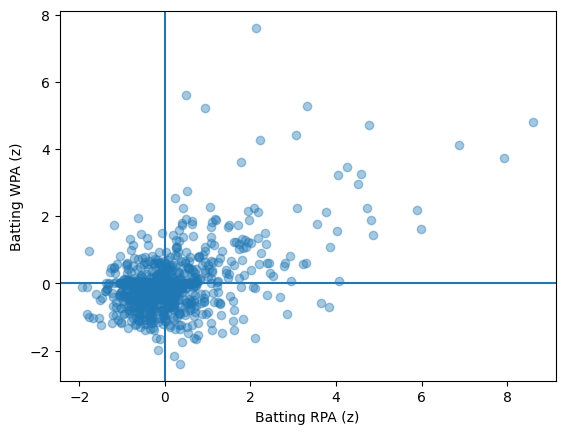

In [8]:
import matplotlib.pyplot as plt

plt.scatter(df["bat_rpa_z"], df["bat_wpa_z"], alpha=0.4)
plt.xlabel("Batting RPA (z)")
plt.ylabel("Batting WPA (z)")
plt.axhline(0)
plt.axvline(0)
plt.show()


In [9]:
df[df["player"].isin([
    "V Kohli",
    "AD Russell",
    "JJ Bumrah",
    "R Ashwin"
])]


,player,bat_rpa_raw,balls_faced_rpa,bowl_rpa_raw,bowl_balls,bat_wpa_raw,bowl_wpa_raw,balls_faced_wpa,balls_bowled,bat_rpa_eligible,bowl_rpa_eligible,bat_wpa_eligible,bowl_wpa_eligible,bat_rpa_z,bowl_rpa_z,bat_wpa_z,bowl_wpa_z,total_player_value
82,AD Russell,854.855416,2438.0,-412.987356,3851.0,5.600601,-4.439123,2342.0,2839.0,True,True,True,True,7.915151,-4.420671,3.741126,-3.807136,3.428470
1364,JJ Bumrah,-6.665292,31.0,471.796587,2070.0,0.000000,4.007605,0.0,2220.0,False,True,False,True,0.000000,5.552593,0.000000,3.376778,8.929371
2479,R Ashwin,0.993856,396.0,-2.803411,2028.0,-0.897176,1.822795,270.0,2110.0,True,True,True,True,-0.318351,0.202913,-0.894892,1.518605,0.508273
3372,V Kohli,264.555313,3698.0,11.624843,11.0,6.360831,-0.000000,3074.0,0.0,True,False,True,False,2.223084,0.000000,4.283533,0.000000,6.506616


adding last active

In [ ]:
# LAST MATCH PLAYED


bb = pd.read_csv(
    "outputs/ball_by_ball_canonical.csv",
    usecols=["batter", "bowler", "date"]
)

bb["date"] = pd.to_datetime(bb["date"])

# Convert to player-date table
player_dates = pd.concat([
    bb[["batter", "date"]].rename(columns={"batter": "player"}),
    bb[["bowler", "date"]].rename(columns={"bowler": "player"})
])

player_dates = player_dates.dropna(subset=["player"])

last_played = (
    player_dates
    .groupby("player")["date"]
    .max()
    .reset_index()
    .rename(columns={"date": "last_match_played"})
)

# Merge into player value table
df = df.merge(last_played, on="player", how="left")


adding teams representated

In [ ]:

# TEAMS REPRESENTED


bb_teams = pd.read_csv(
    "outputs/ball_by_ball_canonical.csv",
    usecols=["batter", "bowler", "batting_team", "bowling_team"]
)

# Batter teams
bat_teams = (
    bb_teams[["batter", "batting_team"]]
    .dropna()
    .rename(columns={"batter": "player", "batting_team": "team"})
)

# Bowler teams
bowl_teams = (
    bb_teams[["bowler", "bowling_team"]]
    .dropna()
    .rename(columns={"bowler": "player", "bowling_team": "team"})
)

player_teams = pd.concat([bat_teams, bowl_teams])

teams_represented = (
    player_teams
    .drop_duplicates()
    .groupby("player")["team"]
    .apply(lambda x: sorted(x.unique()))
    .reset_index()
    .rename(columns={"team": "teams_represented"})
)

# Merge into player table
df = df.merge(teams_represented, on="player", how="left")


In [12]:
df[["player", "last_match_played", "teams_represented"]].head()


,player,last_match_played,teams_represented
0,A Aravinddaraj,2022-10-18,[Puducherry]
1,A Ashish Reddy,2019-02-25,"[Hyderabad (India), Sunrisers Hyderabad]"
2,A Ashok,2025-01-29,[Auckland]
3,A Athanaze,2024-10-04,"[Barbados Royals, West Indies]"
4,A Awasthi,2023-10-23,[Arunachal Pradesh]


In [13]:
df[df["teams_represented"].isna()].shape


(0, 20)

In [16]:
df[df["player"] == "HH Pandya"]


,player,bat_rpa_raw,balls_faced_rpa,bowl_rpa_raw,bowl_balls,bat_wpa_raw,bowl_wpa_raw,balls_faced_wpa,balls_bowled,bat_rpa_eligible,bowl_rpa_eligible,bat_wpa_eligible,bowl_wpa_eligible,bat_rpa_z,bowl_rpa_z,bat_wpa_z,bowl_wpa_z,total_player_value,last_match_played,teams_represented
1096,HH Pandya,56.272101,2078.0,-257.532845,1587.0,-0.768185,-2.941751,1153.0,1842.0,True,True,True,True,0.214678,-2.668392,-0.802861,-2.533626,-5.7902,2025-06-01,"[Baroda, Gujarat Titans, India, Mumbai Indians]"


In [ ]:

OUTPUT_PATH = "outputs/player_total_value_master.csv"

df = df.sort_values("total_player_value", ascending=False)

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print(f"Saved master player value table to: {OUTPUT_PATH}")


Saved master player value table to: outputs/player_total_value_master.csv
